# [LAB-06] 데이터 시각화

## 14-1_Lm Plot

### #01 준비작업

1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import my_plot
import seaborn as sb

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.25


2. 데이터 가져오기

In [2]:
origin = load_data("penguins")
origin

📚 남극 팔머 군도의 펭귄 3종에 대해 신체 치수와 서식지 정보(출처: https://www.kaggle.com/datasets/larsen0966/penguins)

    field              description
--  -----------------  -------------
 0  species            팽귄 종
 1  island             서식지
 2  bill_length_mm     부리 길이
 3  bill_depth_mm      부리 두께
 4  flipper_length_mm  날개 길이
 5  body_mass_g        몸무게
 6  sex                성별



,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181,3750,MALE
1,Adelie,Torgersen,39.500,17.400,186,3800,FEMALE
2,Adelie,Torgersen,40.300,18.000,195,3250,FEMALE
3,Adelie,Torgersen,36.700,19.300,193,3450,FEMALE
4,Adelie,Torgersen,39.300,20.600,190,3650,MALE
...,...,...,...,...,...,...,...
329,Gentoo,Biscoe,47.200,13.700,214,4925,FEMALE
330,Gentoo,Biscoe,46.800,14.300,215,4850,FEMALE
331,Gentoo,Biscoe,50.400,15.700,222,5750,MALE
332,Gentoo,Biscoe,45.200,14.800,212,5200,FEMALE


### #02 Lm Plot

1. Lm Plot 기본 시각화 - 부리 길이와 부리 두께의 관계
- pyplot 객체를 직접 초기화할 수 없다 -> my_plot.init()의 영향을 받지 않는다

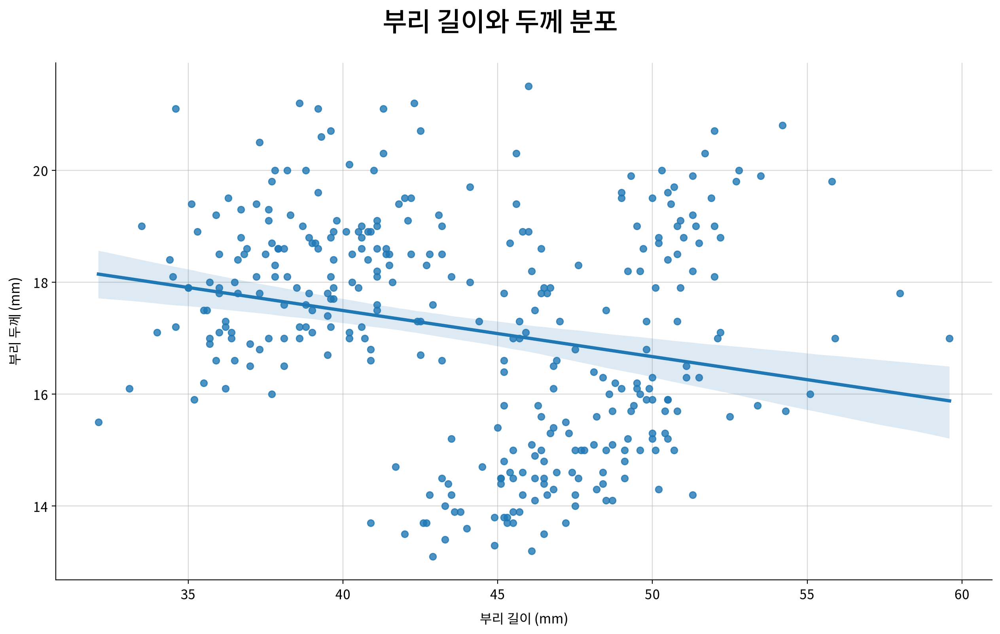

In [3]:
# 1) 그래프 초기화
width = 1280 / 100      # 그래프 가로 크기
height = 800 / 100      # 그래프 세로 크기
my_dpi = 200            # 그래프 해상도

# 2) lmplot 그리기 --> 사이즈를 지정하는 방식이 독특하다
g = sb.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
              height=height,        # 그래프의 높이
              aspect=width/height)  # 그래프의 가로 세로 비율 (width/height)

# 3) 그래프 설정
g.fig.set_dpi(my_dpi)           # 그래프 해상도 설정
g.fig.set_tight_layout(True)    # 여백 제거
g.fig.suptitle('부리 길이와 두께 분포', fontsize=24, fontweight=500, y=1)

# 4) ax 객체 추출 --> 리스트 형태로 추출된다
ax = g.axes.flatten()
ax[0].set_xlabel('부리 길이 (mm)', fontsize=12, labelpad=10)
ax[0].set_ylabel('부리 두께 (mm)', fontsize=12, labelpad=10)
ax[0].grid(True, alpha=0.5)

# 5) 그래프 출력
my_plot.show()

> 인사이트
> - 음의 상관관계:
>   - 부리 길이가 증가할수록 부리 두께가 감소하는 경향을 보임
>   - 회귀선의 음의 기울기로 명확히 확인됨
> - 선형성 강도:
>   - 선형 관계가 존재하지만 개별 데이터의 편차가 상당함
>   - 즉, 부리 길이만으로는 부리 두께를 완벽하게 예측할 수 없음
> - 데이터 범위 및 분포:
>   - 부리 길이: 약 33\~62mm 범위에 분포
>   - 부리 두께: 약 14\~22mm 범위에 분포
>   - 데이터 포인트들이 전체 범위에 걸쳐 비교적 고르게 분포
> - 회귀선의 신뢰도:
>   - x축 중앙부(40\~50mm)에서는 신뢰구간이 좁지만, 양쪽 끝(33mm, 62mm)으로 갈수록 신뢰구간이 넓어짐
>   - 이는 극단값에서의 예측 불확실성이 높음을 의미

2. 마커 모양 설정하기

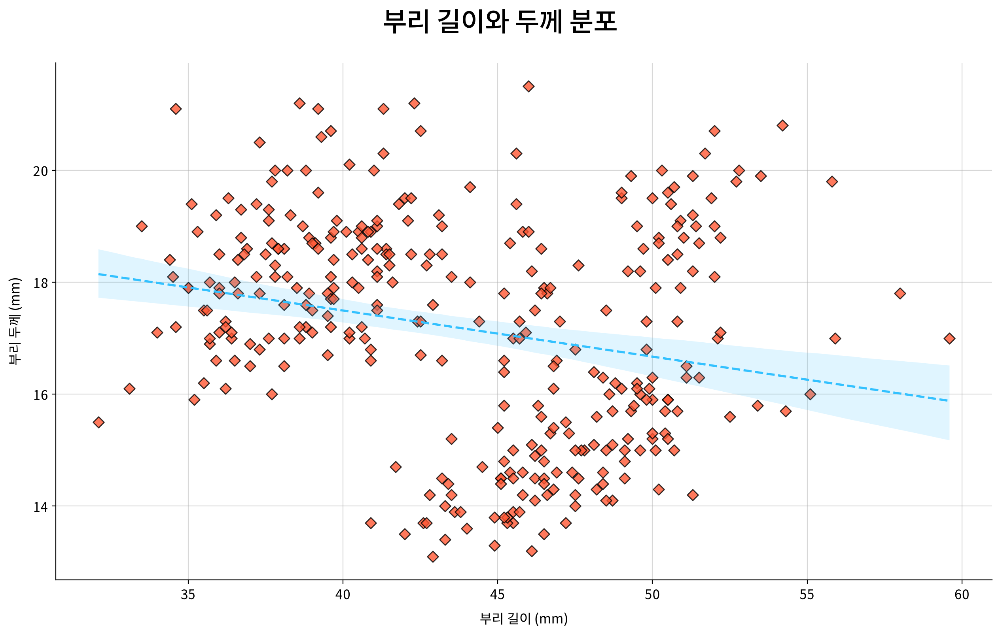

In [4]:
# 1) 그래프 초기화
width = 1280 / 100      # 그래프 가로 크기
height = 800 / 100      # 그래프 세로 크기
my_dpi = 200            # 그래프 해상도

# 2) lmplot 그리기 --> 사이즈를 지정하는 방식이 독특하다
g = sb.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
              height=height,        # 그래프의 높이
              aspect=width/height,  # 그래프의 가로 세로 비율 (width/height)
              markers="D",
              scatter_kws={
                  "edgecolor": "#000000",   # 점 테두리 색상
                  "color": "#FF5733",       # 점 내부 색상
                  "linewidths": 1,            # 점 테두리 두께
                  "s": 50,                    # 점 크기
                  "alpha": 0.8,               # 점 투명도
              },
              line_kws={
                  "color": "#33C1FF",       # 회귀선 색상
                  "linestyle": "--",          # 회귀선 스타일을 점선으로 설정
                  "linewidth": 2,             # 회귀선 두께
              }
)

# 3) 그래프 설정
g.fig.set_dpi(my_dpi)           # 그래프 해상도 설정
g.fig.set_tight_layout(True)    # 여백 제거
g.fig.suptitle('부리 길이와 두께 분포', fontsize=24, fontweight=500, y=1)

# 4) ax 객체 추출 --> 리스트 형태로 추출된다
ax = g.axes.flatten()
ax[0].set_xlabel('부리 길이 (mm)', fontsize=12, labelpad=10)
ax[0].set_ylabel('부리 두께 (mm)', fontsize=12, labelpad=10)
ax[0].grid(True, alpha=0.5)

# 5) 그래프 출력
my_plot.show()

3. 범주 설정하기 - 종별 부리 길이와 부리 두께의 관계

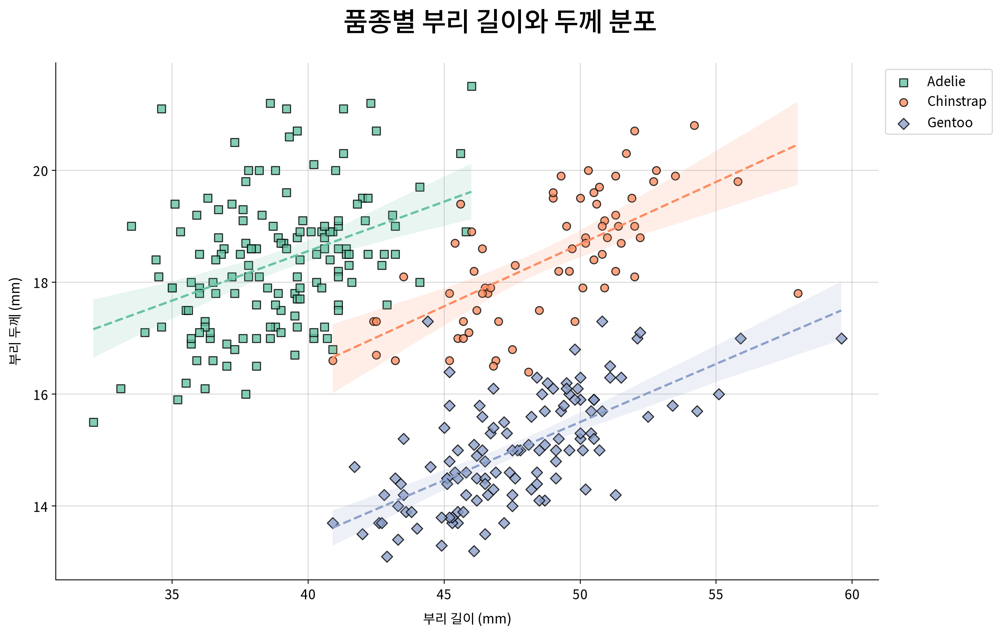

In [5]:
# 1) 그래프 초기화
width = 1280 / 100      # 그래프 가로 크기
height = 800 / 100      # 그래프 세로 크기
my_dpi = 200            # 그래프 해상도

# 2) lmplot 그리기 --> 사이즈를 지정하는 방식이 독특하다
g = sb.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
              height=height,        # 그래프의 높이
              aspect=width/height,  # 그래프의 가로 세로 비율 (width/height)
              hue='species',        # 종별로 색상 구분
              legend=False,         # 범례 제거 (그래프와 겹치기 때문에 수동 설정 권장)
              markers=["s", "o", "D"],  # 마커 모양 개수가 범주의 수와 일치하도록 설정
              palette="Set2",           # 색상 팔레트 설정 가능
              scatter_kws={             # 팔레트가 설정되었으므로 점 색상은 설정하지 않음
                  "edgecolor": "#000000",   # 점 테두리 색상
                  "linewidths": 1,            # 점 테두리 두께
                  "s": 50,                    # 점 크기
                  "alpha": 0.8,               # 점 투명도
              },
              line_kws={                      # 팔레트가 설정되었으므로 회귀선 색상은 설정하지 않음
                  "linestyle": "--",          # 회귀선 스타일을 점선으로 설정
                  "linewidth": 2,             # 회귀선 두께
              }
)

# 3) 그래프 설정
g.fig.set_dpi(my_dpi)           # 그래프 해상도 설정
g.fig.set_tight_layout(True)    # 여백 제거
g.fig.suptitle('품종별 부리 길이와 두께 분포', fontsize=24, fontweight=500, y=1)

# 4) ax 객체 추출 --> 리스트 형태로 추출된다
ax = g.axes.flatten()
ax[0].set_xlabel('부리 길이 (mm)', fontsize=12, labelpad=10)
ax[0].set_ylabel('부리 두께 (mm)', fontsize=12, labelpad=10)
ax[0].grid(True, alpha=0.5)
ax[0].legend(bbox_to_anchor=(1, 1), loc='upper left')   # 범례 위치 조정

# 5) 그래프 출력
my_plot.show()

> **인사이트**
>
> - **종별 상반된 관계**
>   - 종을 구분하지 않으면 음의 상관관계이지만, **종별로 분석하면 양의 상관관계**를 보임
>
> - **종별 특성 차이**
>   - Adelie (녹색):
>     부리 길이 33~46mm,
>     부리 두께 17~20.5mm 범위
>   - Chinstrap (주황):
>     부리 길이 46~58mm,
>     부리 두께 17~20.5mm 범위
>   - Gentoo (파랑):
>     부리 길이 46~61mm,
>     부리 두께 13.5~17.5mm 범위
>
> - **회귀선의 기울기 비교**
>   - Chinstrap의 회귀선 기울기가 가장 가파르고, Gentoo의 기울기가 가장 완만
>   - 이는 **종마다 부리 길이 증가에 따른 두께 변화의 정도가 다름**을 의미

4. 열 구분하기 - 성별에 따른 종별 부리 길이와 부리 두께의 관계

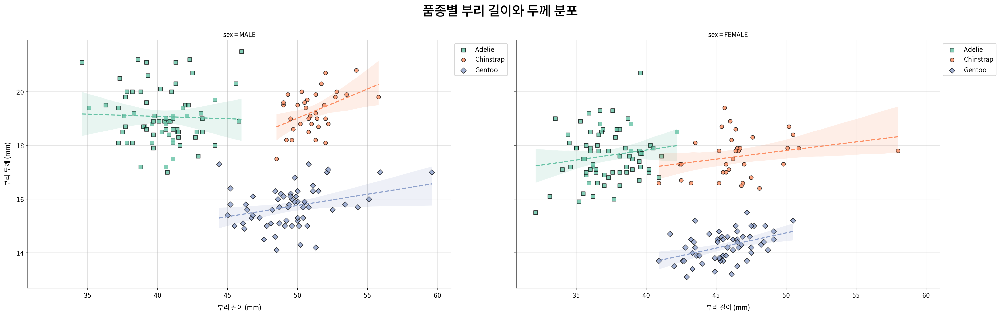

In [6]:
# 1) 그래프 초기화
width = 1280 / 100      # 그래프 가로 크기
height = 800 / 100      # 그래프 세로 크기
my_dpi = 200            # 그래프 해상도

# 2) lmplot 그리기 --> 사이즈를 지정하는 방식이 독특하다
g = sb.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
              height=height,        # 그래프의 높이
              aspect=width/height,  # 그래프의 가로 세로 비율 (width/height)
              hue='species',        # 종별로 색상 구분
              col='sex',            # 성별로 컬럼 분할
              legend=False,         # 범례 제거 (그래프와 겹치기 때문에 수동 설정 권장)
              markers=["s", "o", "D"],  # 마커 모양 개수가 범주의 수와 일치하도록 설정
              palette="Set2",           # 색상 팔레트 설정 가능
              scatter_kws={             # 팔레트가 설정되었으므로 점 색상은 설정하지 않음
                  "edgecolor": "#000000",   # 점 테두리 색상
                  "linewidths": 1,            # 점 테두리 두께
                  "s": 50,                    # 점 크기
                  "alpha": 0.8,               # 점 투명도
              },
              line_kws={                      # 팔레트가 설정되었으므로 회귀선 색상은 설정하지 않음
                  "linestyle": "--",          # 회귀선 스타일을 점선으로 설정
                  "linewidth": 2,             # 회귀선 두께
              }
)

# 3) 그래프 설정
g.fig.set_dpi(my_dpi)           # 그래프 해상도 설정
g.fig.set_tight_layout(True)    # 여백 제거
g.fig.suptitle('품종별 부리 길이와 두께 분포', fontsize=24, fontweight=500, y=1)

# 4) ax 객체 추출 --> 리스트 형태로 추출된다
ax = g.axes.flatten()

# 반복문을 사용하여 분할된 그래프 각각에 레이블과 범례, 그리드 설정
for a in ax:
    a.set_xlabel('부리 길이 (mm)', fontsize=12, labelpad=10)
    a.set_ylabel('부리 두께 (mm)', fontsize=12, labelpad=10)
    a.legend(bbox_to_anchor=(1, 1), loc='upper left')   # 범례 위치 조정
    a.grid(True, alpha=0.5)

# 5) 그래프 출력
my_plot.show()

> **인사이트**
>
> - **성별에 따른 부리 특성 차이:**
>   - 남성 개체가 여성 개체보다 전반적으로 부리 길이가 크고 두께도 더 큼
>   - 이는 종 내에서 성별에 따른 신체 크기 차이 현상
>
> - **성별별 종 구분의 명확성:**
>   - 남성: Adelie(좌상단), Chinstrap(우상단), Gentoo(중앙하단)이 비교적 뚜렷하게 분리됨
>   - 여성: 종 간 겹침이 많아서 구분이 덜 명확함
>   - 특히 Adelie와 Chinstrap이 중첩 영역 존재
>
> - **성별에 따른 상관관계의 강도 차이:**
>   - 남성: Chinstrap의 회귀선 기울기가 가장 가파르고, 신뢰구간이 대체로 좁음 → 종 내 관계가 더 선형적
>   - 여성: 전체적으로 신뢰구간이 넓고 기울기가 완만함 → 개체 간 변동성이 더 큼

### #03 모듈화 기능 확인

1. 기본 산점도

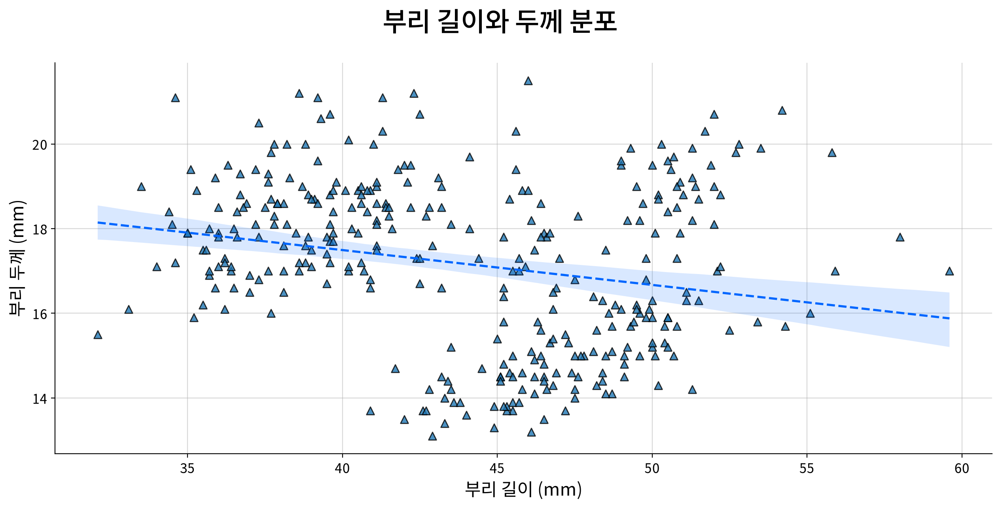

In [7]:
my_plot.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
       title='부리 길이와 두께 분포',
       xlabel='부리 길이 (mm)', ylabel='부리 두께 (mm)',
       markers='^', scatter_edgecolor="#000000", scatter_linewidths=1, scatter_size=50,
       linestyle="--", linecolor="#0066ff", linewidth=2)

2. 범주별 산점도

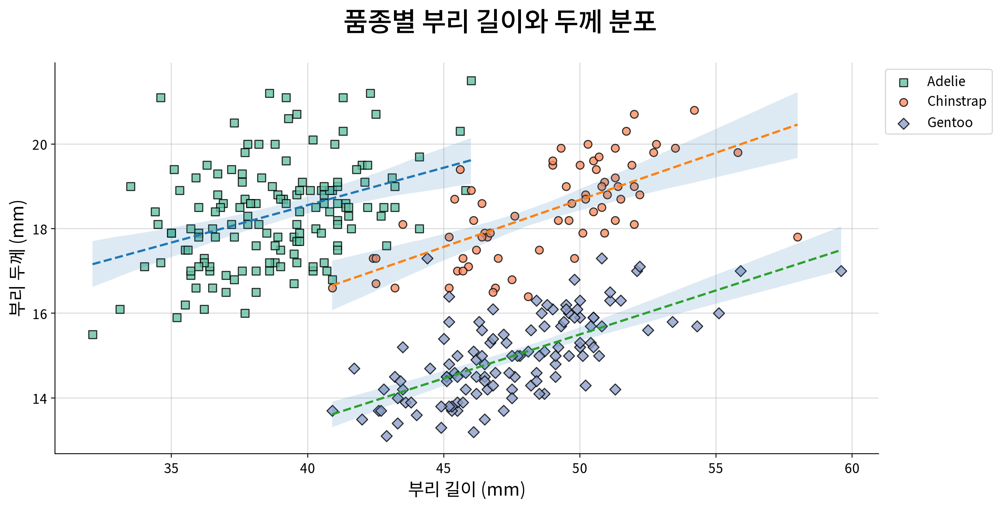

In [8]:
my_plot.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
       title='품종별 부리 길이와 두께 분포',
       xlabel='부리 길이 (mm)', ylabel='부리 두께 (mm)',
       hue='species', palette="Set2",
       markers=["s", "o", "D"],
       scatter_edgecolor="#000000", scatter_linewidths=1, scatter_size=50,
       linestyle="--", linewidth=2)

3. 열로 구성된 범주별 산점도

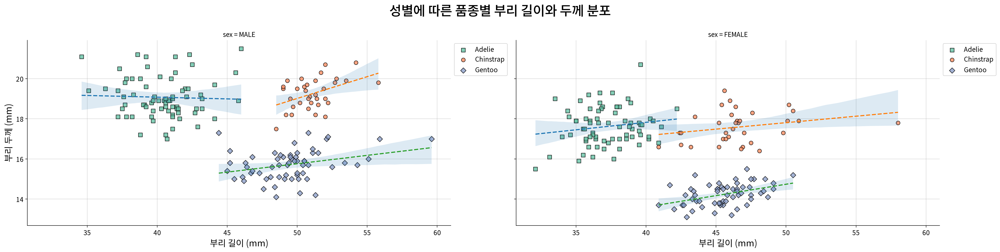

In [9]:
my_plot.lmplot(data=origin, x='bill_length_mm', y='bill_depth_mm',
       title='성별에 따른 품종별 부리 길이와 두께 분포',
       xlabel='부리 길이 (mm)', ylabel='부리 두께 (mm)',
       hue='species', palette="Set2", col="sex",
       markers=["s", "o", "D"],
       scatter_edgecolor="#000000", scatter_linewidths=1, scatter_size=50,
       linestyle="--", linewidth=2)

---

## 연습문제
#### 녹지가 많은 동네는 월세가 비쌀까?

In [10]:
# 라이브러리 참조
from jussam import load_data
from helpers import my_plot
import seaborn as sb

In [11]:
# 데이터 가져오기
origin = load_data("city_districts")
origin

📚 전국 자치구의 녹지율과 평균월세에 대한 가상의 데이터


,권역,도시규모,녹지율,인구밀도,평균월세
0,수도권,중소도시,11.500,17670,108.300
1,영남권,대도시,24.400,12610,98.500
2,호남권,중소도시,29.100,1310,70.300
3,호남권,대도시,29.200,4710,73.900
4,영남권,대도시,19.200,10900,86.600
...,...,...,...,...,...
325,영남권,중소도시,14.800,6300,74.700
326,수도권,대도시,6.300,21430,112.300
327,수도권,중소도시,15.000,17240,109.200
328,영남권,대도시,17.800,11140,92.200


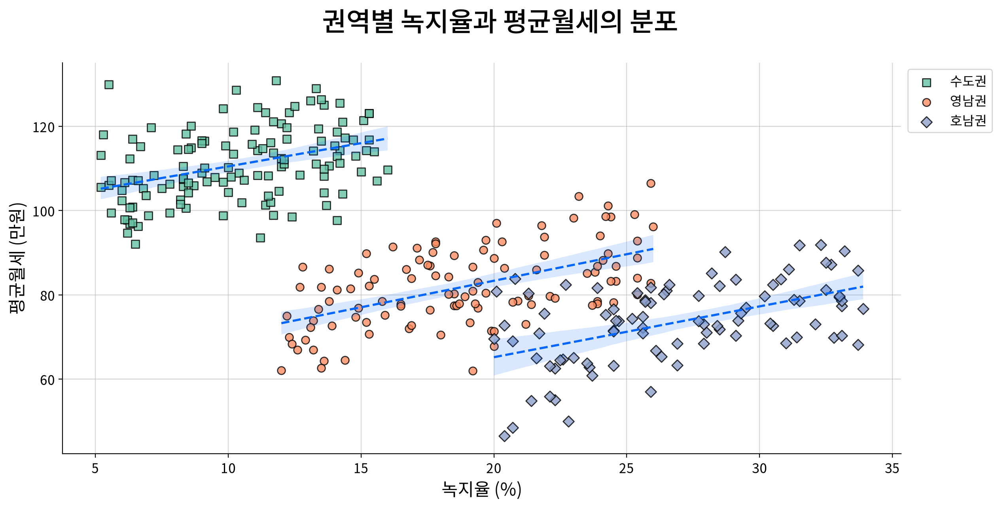

In [12]:
# 권역별 녹지율과 평균 월세의 관계 그래프 그리기
my_plot.lmplot(data=origin, x='녹지율', y='평균월세',
       title='권역별 녹지율과 평균월세의 분포',
       xlabel='녹지율 (%)', ylabel='평균월세 (만원)',
       hue='권역', palette="Set2",
       markers=["s", "o", "D"],
       scatter_edgecolor="#000000", scatter_linewidths=1, scatter_size=50,
       linestyle="--", linecolor="#0066ff", linewidth=2)

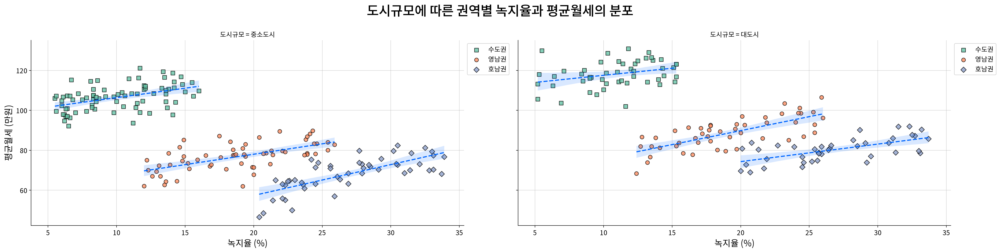

In [13]:
# 도시규모에 따른 권역별 녹지율과 평균 월세의 관계 그래프 그리기
my_plot.lmplot(data=origin, x='녹지율', y='평균월세',
       title='도시규모에 따른 권역별 녹지율과 평균월세의 분포',
       xlabel='녹지율 (%)', ylabel='평균월세 (만원)',
       hue='권역', palette="Set2", col="도시규모",
       markers=["s", "o", "D"],
       scatter_edgecolor="#000000", scatter_linewidths=1, scatter_size=50,
       linestyle="--", linecolor="#0066ff", linewidth=2)

### 문제 답변
1. 권역별로 녹지율이 높아질 수록 평균월세도 높아진다. (양의 관계)
2. 도시규모에 따라 권역별로 녹지율과 평균 월세를 시각화했을 때 대도시의 평균월세가 더 높다.

## 14-2_Pair Plot

### #01 준비작업

1. 라이브러리 참조

In [14]:
from jussam import load_data
from helpers import my_plot
import seaborn as sb

2. 데이터 가져오기

In [15]:
origin = load_data("penguins")
origin

📚 남극 팔머 군도의 펭귄 3종에 대해 신체 치수와 서식지 정보(출처: https://www.kaggle.com/datasets/larsen0966/penguins)

    field              description
--  -----------------  -------------
 0  species            팽귄 종
 1  island             서식지
 2  bill_length_mm     부리 길이
 3  bill_depth_mm      부리 두께
 4  flipper_length_mm  날개 길이
 5  body_mass_g        몸무게
 6  sex                성별



,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181,3750,MALE
1,Adelie,Torgersen,39.500,17.400,186,3800,FEMALE
2,Adelie,Torgersen,40.300,18.000,195,3250,FEMALE
3,Adelie,Torgersen,36.700,19.300,193,3450,FEMALE
4,Adelie,Torgersen,39.300,20.600,190,3650,MALE
...,...,...,...,...,...,...,...
329,Gentoo,Biscoe,47.200,13.700,214,4925,FEMALE
330,Gentoo,Biscoe,46.800,14.300,215,4850,FEMALE
331,Gentoo,Biscoe,50.400,15.700,222,5750,MALE
332,Gentoo,Biscoe,45.200,14.800,212,5200,FEMALE


### #02 Pair Plot 시각화

1. 기본형

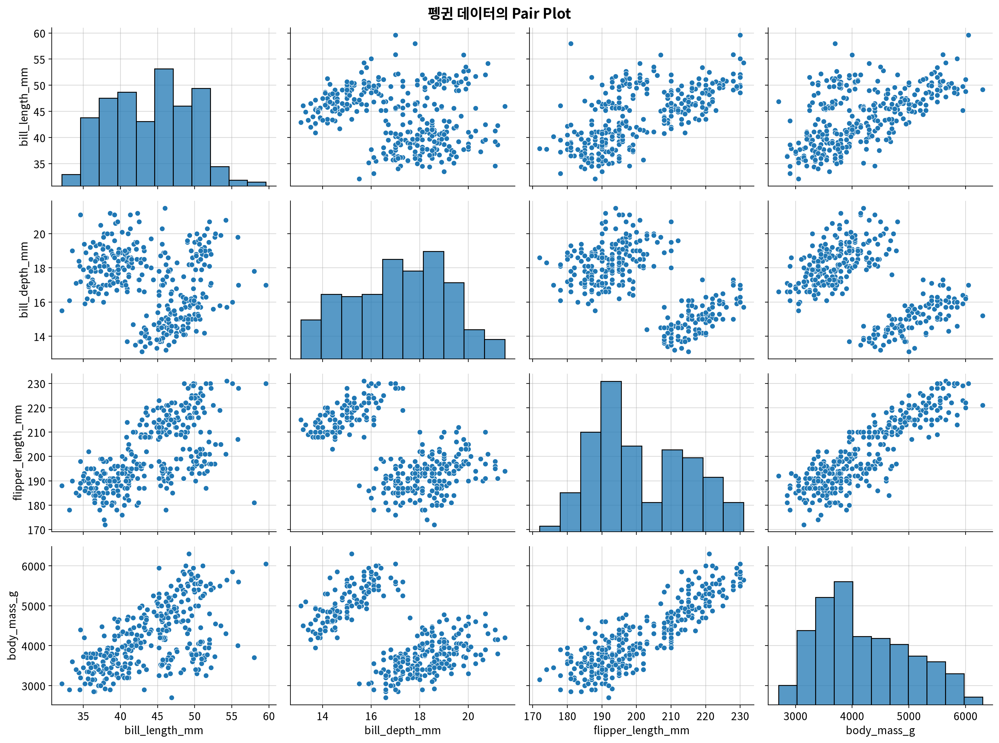

In [16]:
# 1) 그래프 초기화
width = 1600        # 그래프 가로 px 크기
height = 1200       # 그래프 세로 px 크기
my_dpi = 200        # 그래프 해상도 (DPI)

# 그래프 크기를 inch 단위로 변환
figsize = (width / 100, height / 100)

# 2) Pair Plot 그리기
g = sb.pairplot(origin)
g.fig.set_dpi(my_dpi)
g.fig.set_figwidth(figsize[0])
g.fig.set_figheight(figsize[1])

# 제목 추가
g.fig.suptitle("펭귄 데이터의 Pair Plot", fontsize=16, fontweight="bold")

# 3) 개별 그래프 설정
for ax in g.axes.flatten():
    # 격자를 그래프 뒤로 이동
    ax.set_axisbelow(True)
    # 격자 추가
    ax.grid(True, alpha=0.5)

# 4) 출력
my_plot.show()

> **인사이트**
>
> - **강한 양의 상관관계:**
>   - 부리 길이, 지도리 길이, 체중 간 강한 양의 상관관계 관찰
>   - → 이 세 변수는 펭귄의 체형 크기를 함께 나타내는 지표임
>
> - **부리 깊이의 약한 상관관계:**
>   - 부리 깊이는 다른 변수들과 약한 상관관계
>   - → 체형 크기와 독립적인 특성
>
> - **정규분포 근사:**
>   - 대각선 히스토그램에서 모든 변수가 대체로 정규분포에 가까운 형태
>   - → 통계 분석에 유리한 데이터 특성
>
> - **일부 이상치 존재:**
>   - 특히 부리 길이와 체중에서 우측 상단에 떨어진 점들
>   - → 특이한 특성을 가진 개체 존재

2. 범주별 구분 및 마커 모양 설정
- hue 파라미터에 변수를 할당하면 hue 의미론적 매핑이 추가되고 기본 주변 플롯이 계층화된 커널 밀도 추정(KDE)으로 변경된다

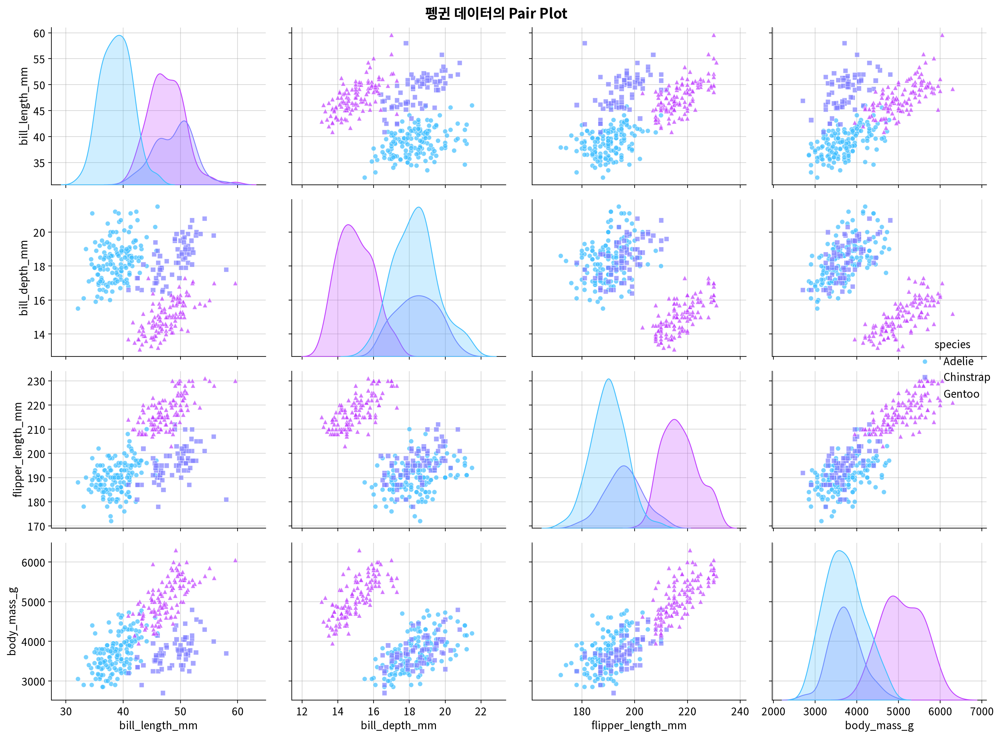

In [17]:
# 1) 그래프 초기화
width = 1600        # 그래프 가로 px 크기
height = 1200       # 그래프 세로 px 크기
my_dpi = 200        # 그래프 해상도 (DPI)

# 그래프 크기를 inch 단위로 변환
figsize = (width / 100, height / 100)

# 2) Pair Plot 그리기
g = sb.pairplot(origin,                             
                hue='species',                      # 범주형 컬럼명 지정
                markers=['o', 's', '^'],            # 종별로 다른 마커 사용
                palette='cool',                     # 종별로 다른 색상 팔레트 사용
                plot_kws={'s': 30, 'alpha': 0.7}    # 마커크기와 투명도
)
g.fig.set_dpi(my_dpi)
g.fig.set_figwidth(figsize[0])
g.fig.set_figheight(figsize[1])

# 제목 추가
g.fig.suptitle("펭귄 데이터의 Pair Plot", fontsize=16, fontweight="bold")

# 3) 개별 그래프 설정
for ax in g.axes.flatten():
    ax.set_axisbelow(True)      # 격자를 그래프 뒤로 이동
    ax.grid(True, alpha=0.5)    # 격자 추가

# 4) 출력
my_plot.show()

3. 회귀선 추가하기

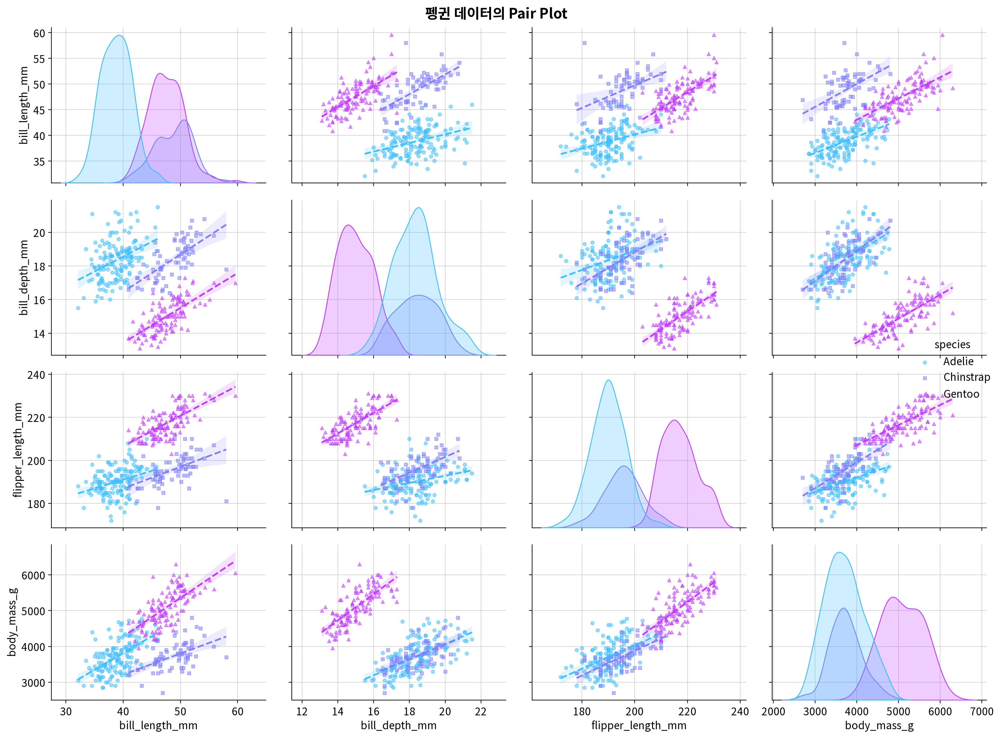

In [18]:
# 1) 그래프 초기화
width = 1600        # 그래프 가로 px 크기
height = 1200       # 그래프 세로 px 크기
my_dpi = 200        # 그래프 해상도 (DPI)

# 그래프 크기를 inch 단위로 변환
figsize = (width / 100, height / 100)

# 2) Pair Plot 그리기
g = sb.pairplot(origin,                             
                hue='species',                      # 범주형 컬럼명 지정
                markers=['o', 's', '^'],            # 종별로 다른 마커 사용
                palette='cool',                     # 종별로 다른 색상 팔레트 사용
                diag_kind='kde',                    # 대각선에 KDE 플롯 사용 (kde 대신 hist 사용)
                kind='reg',                         # 산점도에 회귀선 추가
                # 회귀선을 설정한 경우 모양 설정 방법이 세분화 됨
                plot_kws={
                    # 마커 설정
                    'scatter_kws': {'s': 15, 'alpha': 0.5},
                    # 회귀선 스타일
                    'line_kws': {'linewidth': 2, 'linestyle': '--'}
                },
)
g.fig.set_dpi(my_dpi)
g.fig.set_figwidth(figsize[0])
g.fig.set_figheight(figsize[1])

# 제목 추가
g.fig.suptitle("펭귄 데이터의 Pair Plot", fontsize=16, fontweight="bold")

# 3) 개별 그래프 설정
for ax in g.axes.flatten():
    ax.set_axisbelow(True)      # 격자를 그래프 뒤로 이동
    ax.grid(True, alpha=0.5)    # 격자 추가

# 4) 출력
my_plot.show()

4. 선택적 변수 적용

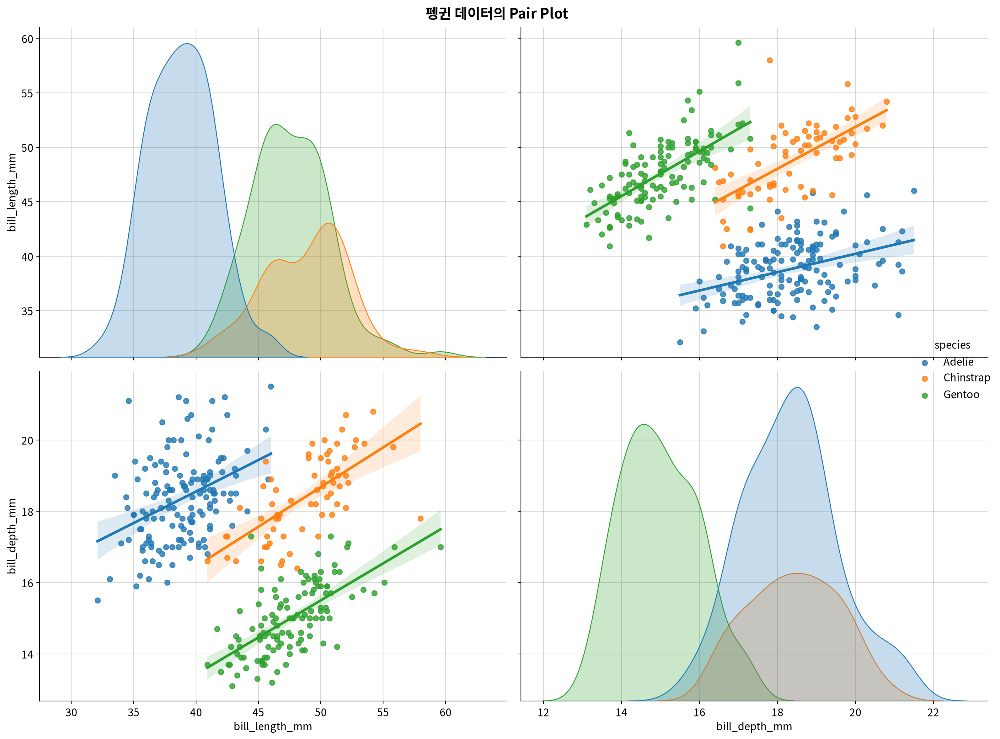

In [19]:
# 1) 그래프 초기화
width = 1600        # 그래프 가로 px 크기
height = 1200       # 그래프 세로 px 크기
my_dpi = 200        # 그래프 해상도 (DPI)

# 그래프 크기를 inch 단위로 변환
figsize = (width / 100, height / 100)

# 2) Pair Plot 그리기
g = sb.pairplot(origin, hue='species', kind='reg', diag_kind='kde',
                x_vars=["bill_length_mm", "bill_depth_mm"],
                y_vars=["bill_length_mm", "bill_depth_mm"]
)

g.fig.set_dpi(my_dpi)
g.fig.set_figwidth(figsize[0])
g.fig.set_figheight(figsize[1])

# 제목 추가
g.fig.suptitle("펭귄 데이터의 Pair Plot", fontsize=16, fontweight="bold")

# 3) 개별 그래프 설정
for ax in g.axes.flatten():
    ax.set_axisbelow(True)      # 격자를 그래프 뒤로 이동
    ax.grid(True, alpha=0.5)    # 격자 추가

# 4) 출력
my_plot.show()

### #03 모듈화 기능 확인

1. 기본 사용

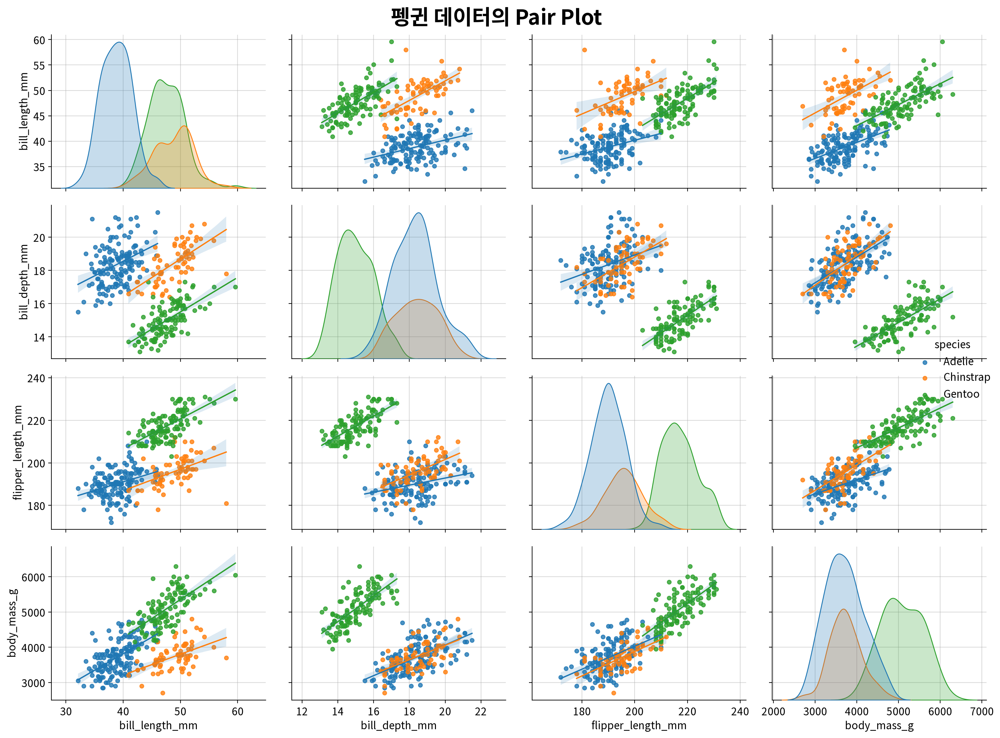

In [20]:
my_plot.pairplot(origin,
                 hue='species',                     # 범주형 컬럼명 지정
                 reg=True,                          # 산점도에 회귀선 추가
                 diag_kind='kde',                   # 대각선에 KDE 플롯 사용
                 title="펭귄 데이터의 Pair Plot",      # 그래프 제목
                 width=1600, height=1200,           # 그래프 크기
                 )

2. 그래프 모양 설정

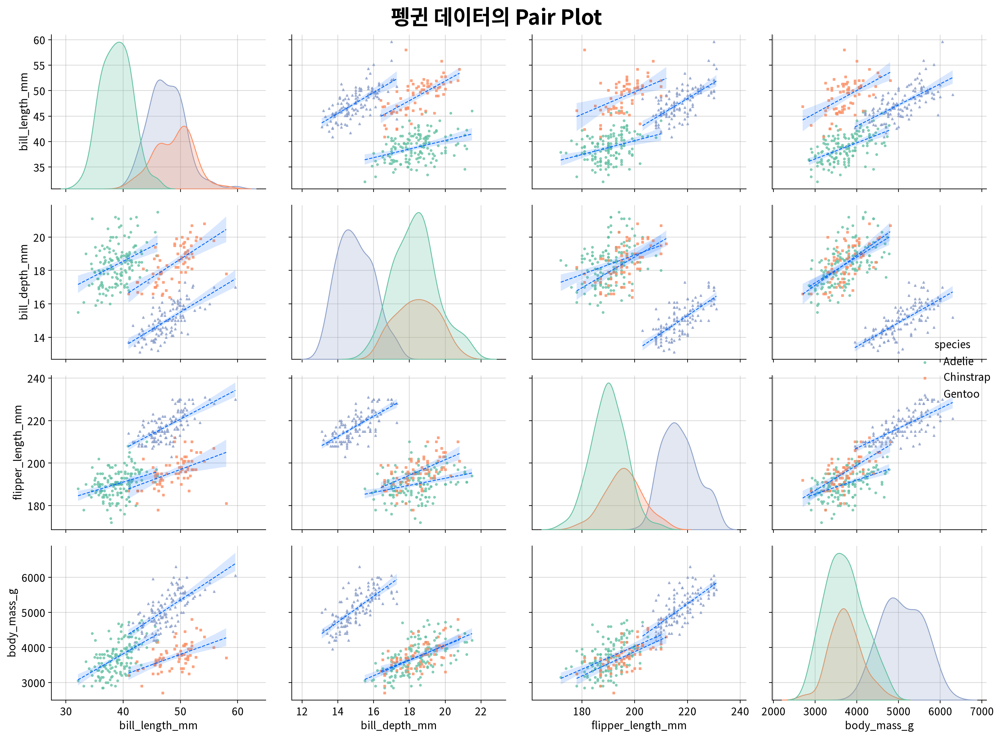

In [21]:
my_plot.pairplot(origin,
                 hue='species',                     # 범주형 컬럼명 지정
                 reg=True,                          # 산점도에 회귀선 추가
                 diag_kind='kde',                   # 대각선에 KDE 플롯 사용
                 title="펭귄 데이터의 Pair Plot",      # 그래프 제목
                 width=1600, height=1200,           # 그래프 크기
                 markers=['o', 's', '^'],           # 종별로 다른 마커 사용
                 palette='Set2',                    # 종별로 다른 색상 팔레트 사용
                 scatter_size=5,                    # 산점도 마커 크기
                 scatter_alpha=0.7,                 # 산점도 마커 투명도
                 linecolor='#0066ff',             # 회귀선 색상
                 linewidth=1,                       # 회귀선 두께
                 linestyle='--'                     # 회귀선 스타일
                 )

---

## 연습문제
### 도시의 덩치를 하나의 그래프로 표현하기

In [22]:
# 라이브러리 참조
from jussam import load_data
from helpers import my_plot
import seaborn as sb

In [24]:
# 데이터 불러오기
origin = load_data("city_stats")
origin

📚 전국 시·군의 도시유형, 인구, 사업체수, 지하철역수, 평균소득에 대한 가상 데이터


,도시유형,인구,사업체수,지하철역수,평균소득
0,일반시,43.500,30.700,27,375.300
1,일반시,16.500,20.400,8,171.300
2,일반시,73.100,65.800,32,185.600
3,군,14.900,9.200,0,287.500
4,일반시,56.100,32.600,19,266.000
...,...,...,...,...,...
295,군,2.000,0.500,0,375.100
296,군,3.200,1.000,4,391.700
297,일반시,54.900,37.600,21,277.900
298,군,3.200,0.500,0,332.600


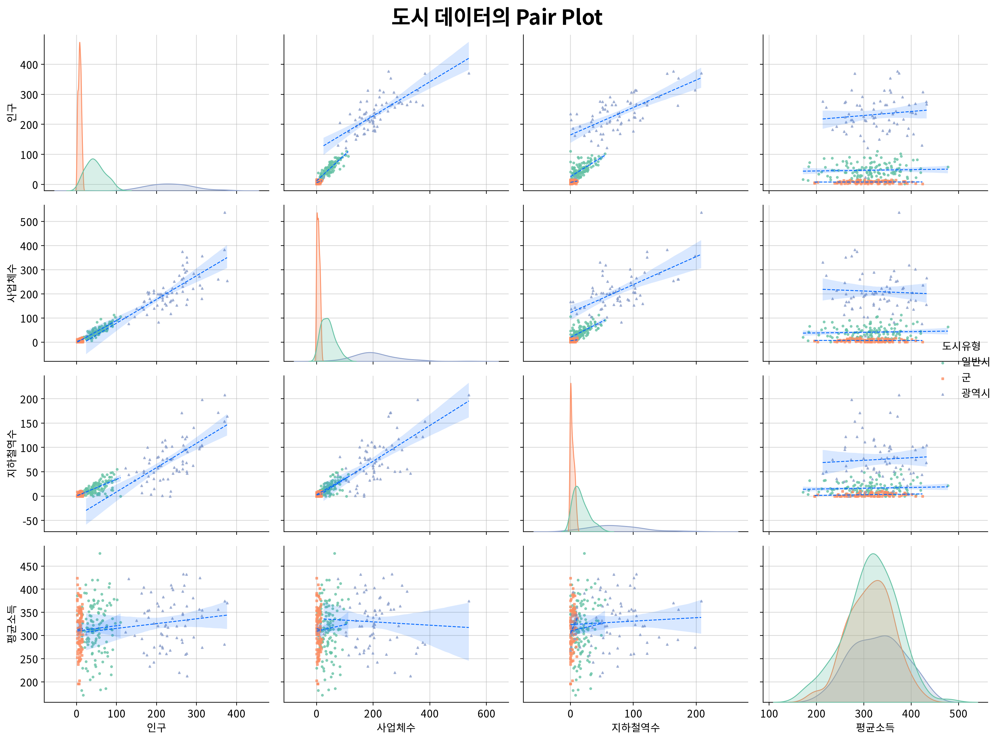

In [25]:
my_plot.pairplot(origin,
                 hue='도시유형',                     # 범주형 컬럼명 지정
                 reg=True,                          # 산점도에 회귀선 추가
                 diag_kind='kde',                   # 대각선에 KDE 플롯 사용
                 title="도시 데이터의 Pair Plot",      # 그래프 제목
                 width=1600, height=1200,           # 그래프 크기
                 markers=['o', 's', '^'],           # 종별로 다른 마커 사용
                 palette='Set2',                    # 종별로 다른 색상 팔레트 사용
                 scatter_size=5,                    # 산점도 마커 크기
                 scatter_alpha=0.7,                 # 산점도 마커 투명도
                 linecolor='#0066ff',             # 회귀선 색상
                 linewidth=1,                       # 회귀선 두께
                 linestyle='--'                     # 회귀선 스타일
                 )

### 문제 답변
> 1. 마케팅팀이 *"인구가 많은 큰 도시일수록 주민의 평균소득도 높을 것"* 이라는 가설을 세웠다. Pair Plot에서 `인구`–`평균소득` 관계를 보고 이 가설이 참인지 거짓인지 판단하라.

- **정답**: 거짓 (인구 규모와 평균소득은 거의 관계가 없다)
- **해설**: 광역시 평균소득(약 329만 원)과 군 평균소득(약 314만 원)은 큰 차이가 없고, 인구–평균소득 상관계수는 약 0.1로 0에 가깝다. Pair Plot에서도 평균소득이 들어간 칸은 점들이 방향 없이 둥글게 흩어져 있다. 즉 **도시가 크다고 해서 주민 소득이 높은 것은 아니다.**
> 2. 어떤 도시의 `인구` 수치만 알고 있을 때, 함께 비교적 정확하게 추정할 수 있는 변수는 무엇인가? (인구와 가장 강하게 같이 움직이는 변수)

- **정답**: 사업체수 (인구와 상관계수 약 0.95로 가장 강함)
- **해설**: 인구는 사업체수와 약 0.95, 지하철역수와 약 0.87의 강한 양의 상관을 보인다. 따라서 인구를 알면 사업체수를 꽤 정확히 추정할 수 있다. 반면 평균소득은 상관이 약 0.1에 불과해 인구로부터 추정하기 어렵다. **인구·사업체수·지하철역수는 사실상 '도시 규모'라는 하나의 특성을 함께 나타낸다.**
> 3. 인구·사업체수·지하철역수 세 지표가 **모두 가장 큰** 도시유형은 무엇인가?

- **정답**: 광역시
- **해설**: 도시유형별 평균을 보면 광역시는 인구 약 233만 명, 사업체수 약 209천 개, 지하철역수 약 75개로 일반시·군을 모든 규모 지표에서 크게 앞선다(군은 인구 약 8만 명, 지하철역수 약 3개). Pair Plot에 `hue='도시유형'` 을 입히면 광역시 점들이 세 규모 변수 산점도 모두에서 오른쪽 위에 몰려 나타나, **규모의 격차가 도시유형 사이에서 매우 크다**는 점을 확인할 수 있다.